In [35]:
import torch 
import torch.nn as nn 
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import matplotlib.pyplot as plt
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(1235)

In [36]:
training_data = datasets.FashionMNIST(
    root = 'data',
    download = True,
    train = True,
    transform = ToTensor()
)
test_data = datasets.FashionMNIST(
    root = 'data',
    download = True,
    train = False,
    transform = ToTensor()
)
train_loader = DataLoader(training_data, batch_size=1024, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1024)

In [37]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super(NeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(784, 128)
        self.linear2 = nn.Linear(128, 128)
        self.output = nn.Linear(128, 10)
    def forward(self, x):
        x = self.flatten(x)
        x = self.linear1(x)
        x = F.relu(x)
        x = self.linear2(x)
        x = F.relu(x)
        ouput = self.output(x)
        return ouput.squeeze(1)
model = NeuralNetwork().to(device)

In [38]:
epochs = 20
learning_rate = 0.01
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.RMSprop(model.parameters(), lr = learning_rate)

In [39]:
def train(dataloader, model, loss_function, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        y_pred = model(X)

        loss = loss_function(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X.size(0)
        correct += (y_pred.argmax(dim = 1) == y).sum().item()
        total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy


In [40]:
def test(dataloader, model, loss_function):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            loss = loss_function(y_pred, y)
            total_loss += loss.item() * X.size(0)
            correct += (y_pred.argmax(dim = 1) == y).sum().item()
            total += y.size(0)
    avg_loss = total_loss / total
    accuracy = correct / total * 100
    return avg_loss, accuracy

In [41]:
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs):
    train_loss, train_accuracy = train(train_loader, model, loss_function, optimizer)
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    test_loss, test_accuracy = test(test_loader, model, loss_function)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    print(
        f'Epoch [{epoch + 1} / {epochs}] |'
        f'Train Loss: {train_loss:.4f} |'
        f'Train Acc: {train_accuracy:.2f}% |'
        f'Test Loss: {test_loss:.4f} |'
        f'Test Acc: {test_accuracy:.2f}%'
    )
print("Training Complete!")

Epoch [1 / 20] |Train Loss: 7.7056 |Train Acc: 54.34% |Test Loss: 1.1988 |Test Acc: 62.25%
Epoch [2 / 20] |Train Loss: 0.7471 |Train Acc: 72.58% |Test Loss: 0.6496 |Test Acc: 77.03%
Epoch [3 / 20] |Train Loss: 0.6382 |Train Acc: 76.40% |Test Loss: 0.5711 |Test Acc: 79.39%
Epoch [4 / 20] |Train Loss: 0.6443 |Train Acc: 76.87% |Test Loss: 0.6143 |Test Acc: 77.93%
Epoch [5 / 20] |Train Loss: 0.5531 |Train Acc: 79.56% |Test Loss: 0.5546 |Test Acc: 79.04%
Epoch [6 / 20] |Train Loss: 0.5291 |Train Acc: 80.69% |Test Loss: 0.6753 |Test Acc: 76.98%
Epoch [7 / 20] |Train Loss: 0.5285 |Train Acc: 80.50% |Test Loss: 0.5587 |Test Acc: 80.52%
Epoch [8 / 20] |Train Loss: 0.5538 |Train Acc: 80.40% |Test Loss: 0.5985 |Test Acc: 78.29%
Epoch [9 / 20] |Train Loss: 0.4710 |Train Acc: 82.68% |Test Loss: 0.4858 |Test Acc: 82.40%
Epoch [10 / 20] |Train Loss: 0.4522 |Train Acc: 83.43% |Test Loss: 0.5302 |Test Acc: 80.67%
Epoch [11 / 20] |Train Loss: 0.6503 |Train Acc: 77.25% |Test Loss: 0.4969 |Test Acc: 82.5

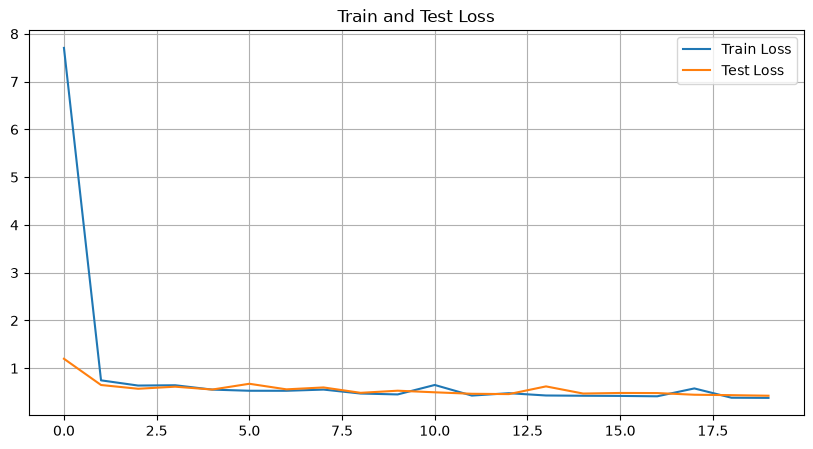

In [42]:
plt.figure(figsize = (10, 5))
plt.plot(train_losses, label = 'Train Loss')
plt.plot(test_losses, label = 'Test Loss')
plt.title('Train and Test Loss')
plt.legend()
plt.grid(True)
plt.show()

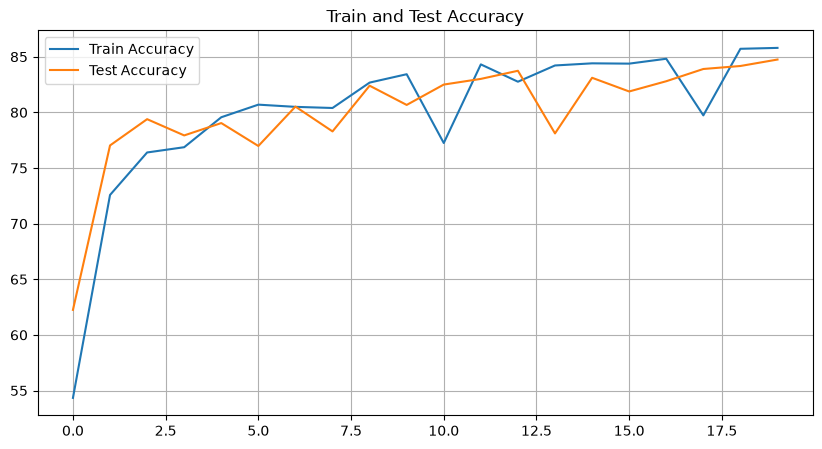

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label = 'Train Accuracy')
plt.plot(test_accuracies, label = 'Test Accuracy')
plt.title('Train and Test Accuracy')
plt.grid(True)
plt.legend()
plt.show()